# Figures for the ALK-TKI potency data descriptorReproduces Figures 1–4 from the published CSV. Nothing is read from an intermediate file, soevery panel is traceable to the deposited data.Run from the repository root. Figures are written to `figures/` as vector PDF and 600 dpi PNG.Two conventions used throughout, both documented in `src/alkdata.py`:- **fold change is computed within context** — against the wild type of a measurement's own  paper, assay, cell line, construct and drug, never a pooled wild type;- **gilteritinib is a comparator**, not an ALK-directed therapeutic. It is shown in the potency  matrix marked with an asterisk and excluded from everything generation-based.

In [1]:
import sys, os
sys.path.insert(0, "src")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats

import alkdata as A
from additivity import table as compound_obs, calibrate, prioritisation_auc

MM = 1/25.4
W1, W15, W2 = 89*MM, 120*MM, 183*MM          # Nature column widths

OI = {"orange":"#E69F00","sky":"#56B4E9","green":"#009E73","yellow":"#F0E442",
      "blue":"#0072B2","verm":"#D55E00","purple":"#CC79A7","grey":"#999999","black":"#000000"}
GEN_C = {1:OI["blue"], 2:OI["sky"], 3:OI["orange"], 4:OI["verm"]}
DRUG_ORDER = ["crizotinib","ceritinib","alectinib","brigatinib","ensartinib","entrectinib",
              "gilteritinib","lorlatinib","repotrectinib","zotizalkib","neladalkib"]

mpl.rcParams.update({
    "font.family":"Helvetica","font.size":7,
    "axes.labelsize":7,"axes.titlesize":7,"xtick.labelsize":6.5,"ytick.labelsize":6.5,
    "legend.fontsize":6.5,"axes.linewidth":0.5,
    "xtick.major.width":0.5,"ytick.major.width":0.5,
    "xtick.major.size":2.0,"ytick.major.size":2.0,
    "axes.spines.top":False,"axes.spines.right":False,
    "legend.frameon":False,"lines.linewidth":0.8,
    "savefig.bbox":"tight","savefig.pad_inches":0.01,
    "pdf.fonttype":42,"ps.fonttype":42})

os.makedirs("figures", exist_ok=True)

def panel(ax, letter, dx=-0.26, dy=1.06):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=9, fontweight="bold",
            va="top", ha="left")

def save(fig, name):
    for ext, kw in (("pdf",{}), ("png",{"dpi":600})):
        fig.savefig(f"figures/{name}.{ext}", **kw)
    print(f"wrote figures/{name}.pdf and .png")

raw = pd.read_csv(A.CSV)
d   = A.load()
h   = A.harmonized(d)
lf  = A.fold_change(d)
print(f"{len(raw):,} records; {len(d):,} uncensored ALK; {len(h)} harmonized")

1,417 records; 1,027 uncensored ALK; 670 harmonized


## Figure 1 — Dataset composition and coverage

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


wrote figures/fig1_composition.pdf and .png


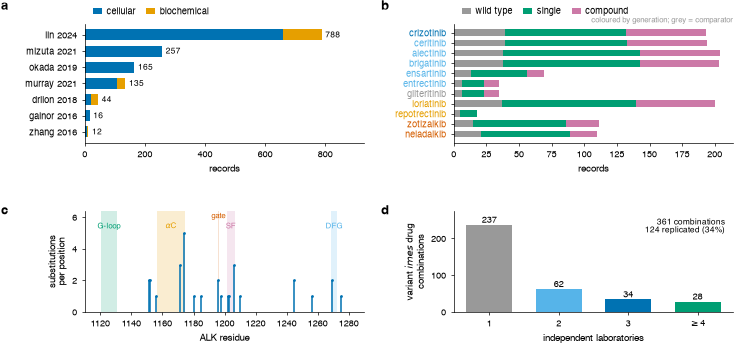

In [2]:
fig = plt.figure(figsize=(W2, 95*MM))
gs = fig.add_gridspec(2, 2, hspace=0.62, wspace=0.32, height_ratios=[1,0.85],
                      left=0.08, right=0.98)

# a — records per source, by assay class
ax = fig.add_subplot(gs[0,0])
t = raw.assign(cls=raw.assay_class.fillna("other")).pivot_table(
        index="paper_id", columns="cls", values="gene", aggfunc="size", fill_value=0)
t = t.loc[t.sum(1).sort_values().index]
left = np.zeros(len(t))
for cls, col in (("cellular",OI["blue"]), ("biochemical",OI["orange"]), ("other",OI["grey"])):
    if cls not in t: continue
    ax.barh(range(len(t)), t[cls], left=left, height=0.68, color=col, label=cls, linewidth=0)
    left = left + t[cls].to_numpy()
ax.set_yticks(range(len(t))); ax.set_yticklabels([i.replace("_"," ") for i in t.index])
ax.set_xlabel("records")
ax.legend(loc="lower left", bbox_to_anchor=(0,1.0), ncol=3, handlelength=1.0,
          handletextpad=0.5, columnspacing=1.2)
for i, tot in enumerate(t.sum(1)):
    ax.text(tot+12, i, f"{tot:,}", va="center", fontsize=6)
ax.set_xlim(0, t.sum(1).max()*1.18)
panel(ax, "a", dx=-0.30, dy=1.20)

# b — records per drug, by variant class
ax = fig.add_subplot(gs[0,1])
a = raw[raw.gene=="ALK"].copy()
vv = a.protein_variant.astype(str).str.strip()
a["klass"] = np.where(vv.str.upper()=="WT", "wild type",
                np.where(vv.str.contains(r"\+"), "compound", "single"))
t = a.pivot_table(index="drug_canonical", columns="klass", values="gene",
                  aggfunc="size", fill_value=0)
t = t.reindex([x for x in DRUG_ORDER if x in t.index])
left = np.zeros(len(t))
for k, col in (("wild type",OI["grey"]), ("single",OI["green"]), ("compound",OI["purple"])):
    if k not in t: continue
    ax.barh(range(len(t)), t[k], left=left, height=0.68, color=col, label=k, linewidth=0)
    left = left + t[k].to_numpy()
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.invert_yaxis()
ax.set_xlabel("records")
ax.legend(loc="lower left", bbox_to_anchor=(0,1.0), ncol=3, handlelength=1.0,
          handletextpad=0.5, columnspacing=1.2)
for lab in ax.get_yticklabels():
    g = A.GENERATION.get(lab.get_text())
    lab.set_color(GEN_C[g] if g else OI["grey"])
ax.text(1.0, 1.0, "coloured by generation; grey = comparator", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=5.6, color=OI["grey"])
panel(ax, "b", dx=-0.26, dy=1.20)

# c — coverage along the kinase domain
ax = fig.add_subplot(gs[1,0])
s = a[vv.str.match(A.SINGLE).fillna(False)].copy()
s["pos"] = vv[s.index].str[1:-1].astype(int)
per = s.groupby("pos")["protein_variant"].nunique()
ax.vlines(per.index, 0, per.to_numpy(), color=OI["blue"], linewidth=1.1)
ax.scatter(per.index, per.to_numpy(), s=4, color=OI["blue"], zorder=3, linewidths=0)
for name, lo, hi, col, lift in (("G-loop",1121,1130,OI["green"],1.06),
                                (r"$\alpha$C",1157,1174,OI["orange"],1.06),
                                ("gate",1196,1196,OI["verm"],1.19),
                                ("SF",1202,1206,OI["purple"],1.06),
                                ("DFG",1269,1272,OI["sky"],1.06)):
    ax.axvspan(lo-0.5, hi+0.5, color=col, alpha=0.18, linewidth=0)
    ax.text((lo+hi)/2, per.max()*lift, name, ha="center", fontsize=5.6, color=col)
ax.set_xlabel("ALK residue"); ax.set_ylabel("substitutions\nper position")
ax.set_ylim(0, per.max()*1.28); ax.set_xlim(1110, 1290)
panel(ax, "c", dx=-0.30)

# d — replication depth
ax = fig.add_subplot(gs[1,1])
combo = h.groupby(["variant","drug_canonical"])["paper_id"].nunique()
tier = [int((combo==1).sum()), int((combo==2).sum()), int((combo==3).sum()), int((combo>=4).sum())]
ax.bar(range(4), tier, color=[OI["grey"],OI["sky"],OI["blue"],OI["green"]], width=0.66, linewidth=0)
for i, n in enumerate(tier):
    ax.text(i, n+max(tier)*0.025, str(n), ha="center", fontsize=6.5)
ax.set_xticks(range(4)); ax.set_xticklabels(["1","2","3","$\geq$4"])
ax.set_xlabel("independent laboratories")
ax.set_ylabel("variant $\times$ drug\ncombinations")
ax.set_ylim(0, max(tier)*1.16)
ax.text(0.97, 0.93, f"{sum(tier)} combinations\n{sum(tier[1:])} replicated "
                    f"({sum(tier[1:])/sum(tier)*100:.0f}%)",
        transform=ax.transAxes, ha="right", va="top", fontsize=6)
panel(ax, "d", dx=-0.26)

save(fig, "fig1_composition"); plt.show()

## Figure 2 — Cross-source concordance

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


wrote figures/fig2_concordance.pdf and .png


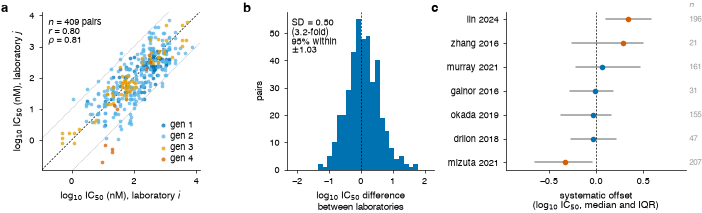

In [3]:
pairs = A.cross_lab_pairs(h)
off   = A.lab_offsets(pairs)

fig = plt.figure(figsize=(W2, 52*MM))
gs = fig.add_gridspec(1, 3, wspace=0.42, width_ratios=[1,0.78,0.95], left=0.07, right=0.985)

ax = fig.add_subplot(gs[0,0])
gen = pairs.drug_canonical.map(A.GENERATION)
for g in sorted(gen.dropna().unique()):
    m = gen == g
    ax.scatter(pairs.loc[m,"log10_nM_i"], pairs.loc[m,"log10_nM_j"], s=7,
               color=GEN_C[int(g)], alpha=0.75, linewidths=0, label=f"gen {int(g)}")
m = gen.isna()
if m.any():
    ax.scatter(pairs.loc[m,"log10_nM_i"], pairs.loc[m,"log10_nM_j"], s=7,
               color=OI["grey"], alpha=0.75, linewidths=0, label="comparator")
lims = [min(pairs.log10_nM_i.min(), pairs.log10_nM_j.min())-0.25,
        max(pairs.log10_nM_i.max(), pairs.log10_nM_j.max())+0.25]
ax.plot(lims, lims, color="k", linewidth=0.5, dashes=(3,2), zorder=0)
for o in (1,-1):
    ax.plot(lims, [lims[0]+o, lims[1]+o], color=OI["grey"], linewidth=0.4,
            dashes=(1.5,1.5), zorder=0)
pr = stats.pearsonr(pairs.log10_nM_i, pairs.log10_nM_j)
sp = stats.spearmanr(pairs.log10_nM_i, pairs.log10_nM_j)
ax.text(0.04, 0.96, f"$n$ = {len(pairs)} pairs\n$r$ = {pr.statistic:.2f}\n"
                    f"$\\rho$ = {sp.statistic:.2f}",
        transform=ax.transAxes, va="top", fontsize=6.5)
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
ax.set_xlabel("log$_{10}$ IC$_{50}$ (nM), laboratory $i$")
ax.set_ylabel("log$_{10}$ IC$_{50}$ (nM), laboratory $j$")
ax.legend(loc="lower right", handlelength=0.8, handletextpad=0.4, borderpad=0.2,
          labelspacing=0.25, markerscale=1.1)
panel(ax, "a", dx=-0.26)

ax = fig.add_subplot(gs[0,1])
diff = pairs.difference.to_numpy()
ax.hist(diff, bins=np.arange(-2.1, 2.2, 0.15), color=OI["blue"], linewidth=0)
ax.axvline(0, color="k", linewidth=0.5, dashes=(3,2))
ax.set_xlabel("log$_{10}$ IC$_{50}$ difference\nbetween laboratories"); ax.set_ylabel("pairs")
ax.text(0.03, 0.96, f"SD = {diff.std():.2f}\n({10**diff.std():.1f}-fold)\n"
                    f"95% within\n$\\pm${np.percentile(abs(diff),95):.2f}",
        transform=ax.transAxes, va="top", fontsize=6.5)
panel(ax, "b", dx=-0.30)

ax = fig.add_subplot(gs[0,2])
for i, r in off.iterrows():
    ax.plot([r.q1, r.q3], [i, i], color=OI["grey"], linewidth=1.1, solid_capstyle="round")
    ax.scatter([r["median"]], [i], s=16, zorder=3, linewidths=0,
               color=OI["verm"] if abs(r["median"])>0.25 else OI["blue"])
    ax.text(1.02, i, f"{int(r.n_pairs)}", transform=ax.get_yaxis_transform(),
            va="center", fontsize=5.8, color=OI["grey"])
ax.axvline(0, color="k", linewidth=0.5, dashes=(3,2))
ax.set_yticks(range(len(off))); ax.set_yticklabels([p.replace("_"," ") for p in off.paper_id])
ax.set_xlabel("systematic offset\n(log$_{10}$ IC$_{50}$, median and IQR)")
ax.set_xlim(-0.95, 0.95)
ax.text(1.02, len(off)-0.4, "$n$", transform=ax.get_yaxis_transform(), va="center",
        fontsize=6, color=OI["grey"])
panel(ax, "c", dx=-0.42)

save(fig, "fig2_concordance"); plt.show()

## Figure 3 — Absolute potency across variants and compoundsCensored records are excluded, so every cell is a measurement rather than a bound. Gilteritinibis included because it is informative, but marked with an asterisk as an off-target comparator.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


wrote figures/fig3_potency_matrix.pdf and .png


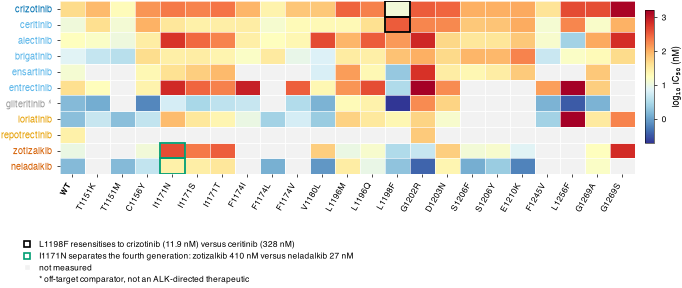

L1198F  crizotinib 11.9 nM   ceritinib 328 nM
I1171N  zotizalkib 410 nM   neladalkib 27 nM


In [4]:
cell = lf[lf.value_type=="Cellular_IC50"]
sing = cell[cell.is_single]
piv = sing.pivot_table(index="variant", columns="drug_canonical", values="value_nM",
                       aggfunc="median")
wt = (A.load(drop_censored=True)
        .pipe(lambda x: x[(x.is_wt) & (x.value_type=="Cellular_IC50")])
        .groupby("drug_canonical")["value_nM"].median())
piv.loc["WT"] = wt
piv = piv.reindex(columns=[c for c in DRUG_ORDER if c in piv.columns])
piv = piv[piv.notna().sum(1) >= 5]
order = sorted([i for i in piv.index if i != "WT"], key=lambda x: int(x[1:-1]))
piv = piv.reindex(["WT"] + order).T

fig = plt.figure(figsize=(W2, 80*MM))
gs = fig.add_gridspec(1, 1, left=0.082, right=0.88, top=0.97, bottom=0.42)
ax = fig.add_subplot(gs[0,0])
M = np.log10(piv.to_numpy(float))
im = ax.imshow(M, cmap="RdYlBu_r", aspect="auto", vmin=-0.7, vmax=3.2, interpolation="nearest")
ax.set_xticks(range(piv.shape[1]))
ax.set_xticklabels(piv.columns, rotation=60, ha="right", fontsize=6)
for lab in ax.get_xticklabels():
    if lab.get_text()=="WT": lab.set_fontweight("bold")
ax.set_yticks(range(len(piv)))
ax.set_yticklabels([(i + " *") if not A.GENERATION.get(i) else i for i in piv.index], fontsize=6.5)
for lab in ax.get_yticklabels():
    g = A.GENERATION.get(lab.get_text().replace(" *",""))
    lab.set_color(GEN_C[g] if g else OI["grey"])
for i in range(len(piv)):
    for j in range(piv.shape[1]):
        if np.isnan(M[i,j]):
            ax.add_patch(plt.Rectangle((j-0.5,i-0.5),1,1, facecolor="#f2f2f2",
                                       edgecolor="white", linewidth=0.4))
ax.set_xticks(np.arange(-0.5, piv.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(piv), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.45); ax.tick_params(which="minor", length=0)
for s_ in ax.spines.values(): s_.set_visible(False)

cols, rows = list(piv.columns), list(piv.index)
def box(variant, drug, col):
    if variant in cols and drug in rows:
        ax.add_patch(plt.Rectangle((cols.index(variant)-0.5, rows.index(drug)-0.5), 1, 1,
                                   fill=False, edgecolor=col, linewidth=1.3, zorder=5))
for drug in ("crizotinib","ceritinib"): box("L1198F", drug, OI["black"])
for drug in ("zotizalkib","neladalkib"): box("I1171N", drug, OI["green"])

cax = fig.add_axes([0.895, 0.52, 0.012, 0.42])
cb = fig.colorbar(im, cax=cax); cb.set_label("log$_{10}$ IC$_{50}$ (nM)", fontsize=6.5)
cb.ax.tick_params(labelsize=6); cb.outline.set_linewidth(0.4)

cri, cer = piv.loc["crizotinib","L1198F"], piv.loc["ceritinib","L1198F"]
zo, ne   = piv.loc["zotizalkib","I1171N"], piv.loc["neladalkib","I1171N"]
leg = [Line2D([],[],marker="s",markerfacecolor="none",markeredgecolor=OI["black"],
              markeredgewidth=1.2,linestyle="none",markersize=5,
              label=f"L1198F resensitises to crizotinib ({cri:.1f} nM) versus ceritinib ({cer:.0f} nM)"),
       Line2D([],[],marker="s",markerfacecolor="none",markeredgecolor=OI["green"],
              markeredgewidth=1.2,linestyle="none",markersize=5,
              label=f"I1171N separates the fourth generation: zotizalkib {zo:.0f} nM versus neladalkib {ne:.0f} nM"),
       Line2D([],[],marker="s",markerfacecolor="#f2f2f2",markeredgecolor="white",
              linestyle="none",markersize=5, label="not measured"),
       Line2D([],[],marker="None",linestyle="none",
              label="* off-target comparator, not an ALK-directed therapeutic")]
ax.legend(handles=leg, loc="upper left", bbox_to_anchor=(-0.085,-0.34), ncol=1,
          handletextpad=0.5, labelspacing=0.45, fontsize=6)

save(fig, "fig3_potency_matrix"); plt.show()
print(f"L1198F  crizotinib {cri:.1f} nM   ceritinib {cer:.0f} nM")
print(f"I1171N  zotizalkib {zo:.0f} nM   neladalkib {ne:.0f} nM")

## Figure 4 — Compound-mutation additivity

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


wrote figures/fig4_compound_additivity.pdf and .png


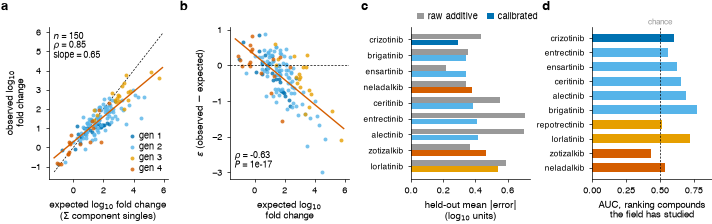

calibration: observed = +0.290 + 0.652 x expected
naive MAE 0.50 -> calibrated 0.37 log10


In [5]:
c = compound_obs(d)
loo, full = calibrate(c)
pa = prioritisation_auc(d)

fig = plt.figure(figsize=(W2, 53*MM))
gs = fig.add_gridspec(1, 4, wspace=0.52, left=0.055, right=0.975, top=0.84)

ax = fig.add_subplot(gs[0,0])
for g in sorted(c.generation.unique()):
    m = c.generation == g
    ax.scatter(c.loc[m,"expected"], c.loc[m,"observed"], s=8, color=GEN_C[int(g)],
               alpha=0.8, linewidths=0, label=f"gen {int(g)}")
xs = np.linspace(c.expected.min()-0.2, c.expected.max()+0.2, 50)
ax.plot(xs, xs, color="k", linewidth=0.5, dashes=(3,2), zorder=0)
ax.plot(xs, full.intercept + full.slope*xs, color=OI["verm"], linewidth=1.0, zorder=1)
ax.text(0.04, 0.96, f"$n$ = {len(c)}\n$\\rho$ = "
                    f"{stats.spearmanr(c.expected, c.observed).statistic:.2f}\n"
                    f"slope = {full.slope:.2f}",
        transform=ax.transAxes, va="top", fontsize=6.3)
ax.set_xlabel("expected log$_{10}$ fold change\n($\\Sigma$ component singles)")
ax.set_ylabel("observed log$_{10}$\nfold change")
ax.legend(loc="lower right", handlelength=0.8, handletextpad=0.4, borderpad=0.15,
          labelspacing=0.2)
panel(ax, "a", dx=-0.40, dy=1.17)

ax = fig.add_subplot(gs[0,1])
for g in sorted(c.generation.unique()):
    m = c.generation == g
    ax.scatter(c.loc[m,"expected"], c.loc[m,"epsilon"], s=8, color=GEN_C[int(g)],
               alpha=0.8, linewidths=0)
ax.axhline(0, color="k", linewidth=0.5, dashes=(3,2))
lr2 = stats.linregress(c.expected, c.epsilon)
ax.plot(xs, lr2.intercept + lr2.slope*xs, color=OI["verm"], linewidth=1.0)
rr = stats.spearmanr(c.expected, c.epsilon)
ax.text(0.04, 0.06, f"$\\rho$ = {rr.statistic:.2f}\n$P$ = {rr.pvalue:.0e}",
        transform=ax.transAxes, va="bottom", fontsize=6.3)
ax.set_xlabel("expected log$_{10}$\nfold change")
ax.set_ylabel("$\\epsilon$ (observed $-$ expected)")
panel(ax, "b", dx=-0.42, dy=1.17)

ax = fig.add_subplot(gs[0,2])
L = loo.sort_values("mae_calibrated")
y = np.arange(len(L))
ax.barh(y-0.19, L.mae_naive, height=0.36, color=OI["grey"], label="raw additive", linewidth=0)
ax.barh(y+0.19, L.mae_calibrated, height=0.36,
        color=[GEN_C[int(g)] for g in L.generation], label="calibrated", linewidth=0)
ax.set_yticks(y); ax.set_yticklabels(L.drug, fontsize=6); ax.invert_yaxis()
ax.set_xlabel("held-out mean $|$error$|$\n(log$_{10}$ units)")
ax.legend(loc="lower left", bbox_to_anchor=(0,1.0), ncol=2, handlelength=0.8,
          handletextpad=0.4, borderpad=0.15, columnspacing=1.0)
panel(ax, "c", dx=-0.42, dy=1.17)

ax = fig.add_subplot(gs[0,3])
P = pa.sort_values(["generation","auc"])
y = np.arange(len(P))
ax.barh(y, P.auc, height=0.62, color=[GEN_C[int(g)] for g in P.generation], linewidth=0)
ax.axvline(0.5, color="k", linewidth=0.5, dashes=(3,2))
ax.set_yticks(y); ax.set_yticklabels(P.drug, fontsize=6); ax.invert_yaxis()
ax.set_xlim(0, 0.88)
ax.set_xlabel("AUC, ranking compounds\nthe field has studied")
ax.text(0.5, -0.95, "chance", fontsize=5.8, color=OI["grey"], ha="center")
panel(ax, "d", dx=-0.42, dy=1.17)

save(fig, "fig4_compound_additivity"); plt.show()
print(f"calibration: observed = {full.intercept:+.3f} + {full.slope:.3f} x expected")
print(f"naive MAE {np.mean(np.abs(c.expected-c.observed)):.2f} -> calibrated "
      f"{np.abs(full.intercept+full.slope*c.expected-c.observed).mean():.2f} log10")